In [74]:
%load_ext autoreload
%autoreload 2

import numpy as np 
import functions 

from matplotlib import pyplot as plt

import importlib
import functions
import scattering_model

importlib.reload(functions)
importlib.reload(scattering_model)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


<module 'scattering_model' from '/Users/peytaguo/Desktop/ASC/Nucelar Resonance Analysis /scattering_model.py'>

In [3]:
ne_amu = 19.9869544
a_amu = 4.001506179129

mg_amu = 23.9784588
uc2 = 931.494 #MeV

energy_threshold = (ne_amu + a_amu - mg_amu)*uc2
print(energy_threshold)

9.316597247987401


In [75]:
sigma = np.load("data/peyta_sigma1.npy")
dsigma = np.load("data/peyta_dsigma1.npy")
theta_cm = np.load("data/peyta_theta_cm1.npy")
ke_cm = np.load("data/peyta_ke_cm1.npy")

rounded_theta_cm = np.round(theta_cm, 1)
rounded_theta_cm[rounded_theta_cm == 53.2] = 53.1
rounded_theta_cm[rounded_theta_cm == 143.2] = 143.1
rounded_theta_cm[rounded_theta_cm == 155.7] = 155.8

print( np.unique( rounded_theta_cm ) )
print(len(np.unique(rounded_theta_cm)))

[ 53.1  58.8  70.   75.5  86.2  91.4 101.6 106.5 116.2 125.5 130.  138.8
 143.1 155.8 163.9 168. ]
16


In [76]:
all_cs = functions.get_all_cs(rounded_theta_cm, ke_cm, sigma, dsigma, 9.31)
#functions.visualise_all_peaks(all_cs)

In [78]:
clusters_dp_chosen = functions.get_clusters_dp(all_cs, 0.001, 0.005)

In [86]:
clusters_dp_chosen[0]

[np.float64(13.32186782827972),
 [[58.8, np.float64(13.315620272331726), np.float64(0.48017776796147543)],
  [53.1, np.float64(13.328115384227713), np.float64(0.696244297387564)]]]

In [ ]:
get_cluster_widths = functions.cluster_widths(clusters_dp_chosen)

In [89]:
print(cluster_widths)

[np.float64(0.5882110326745197), np.float64(0.21502234971906908), np.float64(0.22404544638316043), np.float64(0.14842932725341335), np.float64(0.2887877928842559), np.float64(0.46457282232730623), np.float64(0.4130118465369318), np.float64(0.21977864251116744), np.float64(0.18062073106750412), np.float64(0.1074193428747943), np.float64(0.29433216146872926), np.float64(0.29264734526383174), np.float64(0.12565732894824128), np.float64(0.1426029908628251), np.float64(0.11867418277900242), np.float64(0.11344606160258318), np.float64(0.2303478985834464), np.float64(0.27437044037754765), np.float64(0.11245758371369412), np.float64(0.12062146993529653), np.float64(0.40713033975048735), np.float64(0.20765703078904146), np.float64(0.05777081557979094), np.float64(0.12613308803935433), np.float64(0.21787401499268236), np.float64(0.14436542106835096), np.float64(0.10700909365431618), np.float64(0.3662757891049315), np.float64(0.21793697237700896), np.float64(0.11587513682729775), np.float64(0.307

In [ ]:
#functions.get_dp_clusters_info(clusters_dp_chosen)

In [69]:
print(all_cs.items())

dict_items([('53.1', {'ke': array([13.30312496, 13.31562058, 13.3281162 , 13.3406118 , 13.3531074 ,
       13.36560299, 13.37809858, 13.39059416, 13.40308973, 13.40558884,
       13.40808796, 13.41058707, 13.41308618, 13.41558529, 13.41808441,
       13.42058352, 13.42308263, 13.42558174, 13.42808085, 13.42808085,
       13.43057996, 13.43307907, 13.43557818, 13.4405764 , 13.45307195,
       13.46556748, 13.47806301, 13.49055853, 13.50305405, 13.51554956,
       13.52804506, 13.54054056, 13.55303604, 13.56553152, 13.578027  ,
       13.59052246, 13.60301792, 13.61551338, 13.62800882, 13.64050426,
       13.65383272, 13.66549512, 13.67882356, 13.69131897, 13.71464372,
       13.73213726, 13.73463634, 13.73713542, 13.73963449, 13.74213357,
       13.75379592, 13.76629129, 13.77878665, 13.791282  , 13.80377735,
       13.81627269, 13.83043407, 13.83876429, 13.8470945 , 13.85542471,
       13.85958982, 13.86375492, 13.86792003, 13.87208513, 13.87625023,
       13.88041533, 13.88458043, 13.

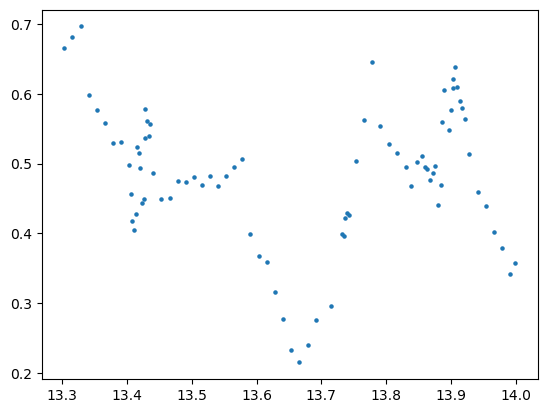

In [68]:
angles = list(all_cs.keys())

#all_cs[angles[0]].keys() -> 'ke', 'sigma', 'dsigma'

sigma_531 = all_cs[angles[0]]['sigma']
ke_531 = all_cs[angles[0]]['ke']

E_min, E_max = 13, 14

mask = (ke_531 >= E_min) & (ke_531 <= E_max)

E_window = ke_531[mask]
sigma_window = sigma_531[mask]

plt.scatter(
    E_window, 
    sigma_window,
    s=5
)
plt.show()

/var/folders/64/560xbkqj7xxf0gnjkybhj9mr0000gn/T/ipykernel_1852/3301661300.py:39: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


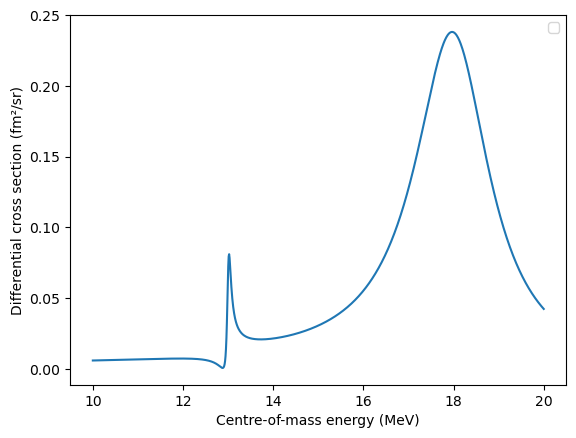

In [36]:
#testing

resonances = [
    {
        "angular m" : 2,
        "p width ratio" : 0.3,
        "width": 0.1,
        "r energy": 13,
        "a": 0.0,
        "b": 0.0
    },
    {
            "angular m" : 5,
            "p width ratio" : 0.2,
            "width": 2,
            "r energy": 18,
            "a": 0.0,
            "b": 0.0
        }
]

energy = np.linspace(10, 20, 1000)
theta = np.deg2rad(45)

sigma = scattering_model.model(
    theta,
    energy,
    resonances,
    m=0,
    c=0
)

import matplotlib.pyplot as plt

plt.plot(energy, sigma)

plt.xlabel("Centre-of-mass energy (MeV)")
plt.ylabel("Differential cross section (fm²/sr)")
plt.legend()
plt.show()

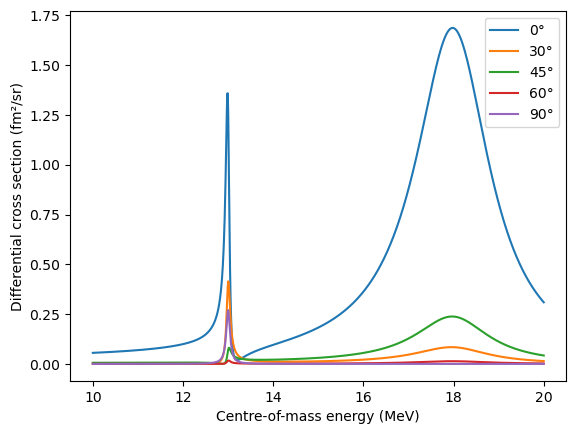

In [37]:
for angle in [0, 30, 45, 60, 90]:
    sigma = scattering_model.model(
        np.deg2rad(angle),
        energy,
        resonances,
        m=0,
        c=0
    )

    plt.plot(energy, sigma, label=f"{angle}°")

plt.xlabel("Centre-of-mass energy (MeV)")
plt.ylabel("Differential cross section (fm²/sr)")
plt.legend()
plt.show()